**Цель работы:** Пройти полный цикл решения задачи регрессии: от первичного анализа данных и простого baseline до сравнения нескольких моделей и анализа результатов.

**Минимальный порог качества: RMSE < 0.70**

# Знакомство с данными

После основных результатов должны быть краткие содержательные выводы

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

RS = 42  # фиксируем воспроизводимость

df = pd.read_csv("data/winequality-red.csv", sep=";")

print("Размер данных:", df.shape, "| пропусков:", df.isna().sum().sum(), "| дубликатов:", df.duplicated().sum())
df.describe().T.round(2)

Размер данных: (1599, 12) | пропусков: 0 | дубликатов: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.32,1.74,4.60,7.10,7.90,9.20,15.90
volatile acidity,1599.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1599.0,0.27,0.19,0.00,0.09,0.26,0.42,1.00
residual sugar,1599.0,2.54,1.41,0.90,1.90,2.20,2.60,15.50
chlorides,1599.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1599.0,15.87,10.46,1.00,7.00,14.00,21.00,72.00
total sulfur dioxide,1599.0,46.47,32.90,6.00,22.00,38.00,62.00,289.00
density,1599.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1599.0,3.31,0.15,2.74,3.21,3.31,3.40,4.01
sulphates,1599.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


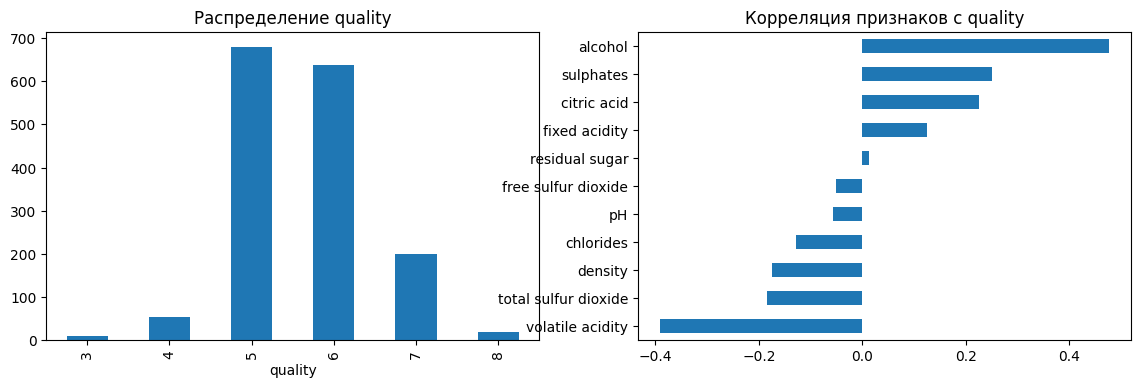

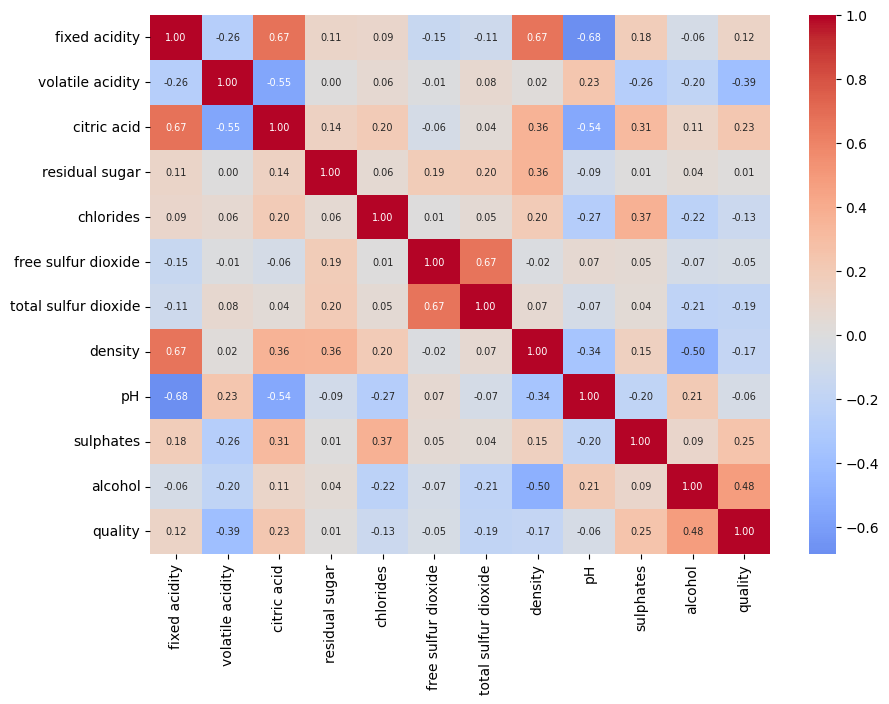

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df["quality"].value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение quality")
df.corr()["quality"].drop("quality").sort_values().plot.barh(ax=ax[1], title="Корреляция признаков с quality")  # барчарт корреляций, показывает связь каждого признака с quality
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})  # тепловая карта корреляций, показывает мультиколлинеарность
plt.show()

**Выводы по первичному анализу данных**

1. **Данные чистые, но с повторами.** 1599 вин, 11 физико-химических признаков, все числовые, пропусков нет. Около 15% строк (≈ 240) - полные дубликаты. Мы их не удаляем, но учитываем: при случайном разбиении копии одной строки попадут и в train, и в test, поэтому оценка качества (особенно у деревьев, умеющих «запоминать» объекты) будет немного оптимистичной.
2. **Целевая переменная - дискретная порядковая оценка, сильно сконцентрированная в середине.** Оценки 5 (≈ 43%) и 6 (≈ 40%) вместе дают ≈ 82% выборки; оценок 3 всего 10, оценок 8 - 18, а оценок ниже 3 и выше 8 нет вовсе. Среднее ≈ 5.6, стандартное отклонение ≈ 0.81. 

   Следствия: 
    - константа уже даёт сравнительно небольшую ошибку (≈ 0.8); 
    - модели будут «тянуть» предсказания к 5–6 и плохо предсказывать редкие оценки - это нужно проверить в анализе ошибок.
3. **Самый сильный сигнал - `alcohol` (r ≈ +0.48):** более крепкие вина дегустаторы в среднем оценивают выше. Затем идут `volatile acidity` (≈ −0.39), `sulphates` (≈ +0.25), `citric acid` (≈ +0.23), `total sulfur dioxide` (≈ −0.19) и `density` (≈ −0.17). 
   Летучая кислотность отвечает за уксусный запах (это дефект), поэтому знак минус здесь объясним; сульфаты (консервант) и лимонная кислота (свежесть) связаны с оценкой положительно. Эти признаки оставляем в моделях.
4. **Все связи умеренные (|r| < 0.5).** Даже `alcohol` объясняет лишь ≈ 23% дисперсии quality, поэтому идеальной точности ждать нельзя: часть оценки определяется тем, чего в данных нет (аромат, сорт, субъективность дегустатора). Кроме того, `residual sugar` (≈ 0.01), `free sulfur dioxide` (≈ −0.05) и `pH` (≈ −0.06) почти не коррелируют с quality. 
   Но низкая корреляция не означает бесполезность признака: коэффициент Пирсона ловит только линейную монотонную связь. Например, у `free sulfur dioxide` связь может быть немонотонной (мало SO₂ - риск порчи, много - ухудшает вкус). Поэтому слабокоррелированные признаки не отбрасываем.
5. **Есть мультиколлинеарность.** `fixed acidity` тесно связана с `density` (≈ +0.67), `citric acid` (≈ +0.67) и `pH` (≈ −0.68; с точки зрения химии это объяснимо: больше кислоты - ниже pH), `free` и `total sulfur dioxide` связаны между собой (≈ +0.67), `density` связана с `alcohol` (≈ −0.50). 
   
   Для линейной регрессии это опасно (неустойчивые коэффициенты, сложная интерпретация), для деревьев менее критично, но важность делится между скоррелированными признаками.
6. **У ряда признаков тяжёлые правые хвосты** (`residual sugar`, `chlorides`, `total sulfur dioxide`, `sulphates`) сравнение max с 50% (медианой) и 75% (верхним квартилем) даёт информацию о хвосте распределения, максимум многократно превышает медиану. 

   Для линейной модели это выбросы, деревья же к ним устойчивы.

# Подготовка выборок

- Разделить данные на обучающую и тестовую части.
- Зафиксировать random_state, чтобы эксперимент можно было воспроизвести.

In [3]:
X, y = df.drop(columns="quality"), df["quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)  
# стратификация по y: сохраняем пропорции классов quality в train и test

print("train:", X_train.shape, "| test:", X_test.shape)
pd.concat([y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)],
          axis=1, keys=["train", "test"]).sort_index().round(3)
# сравниваем доли классов quality в train и test

train: (1279, 11) | test: (320, 11)


,train,test
quality,,
3,0.006,0.006
4,0.033,0.034
5,0.426,0.425
6,0.399,0.400
7,0.124,0.125
8,0.012,0.009


**Параметры разбиения**

- **Размер: 80% / 20%**. Обучающей части достаточно, чтобы деревья и бустинг не страдали от нехватки данных, а на 320 объектах оценка RMSE получается достаточно устойчивой.
- **Способ: случайное разбиение со стратификацией по `quality`.** Объекты независимы, поэтому случайного разбиения достаточно. 

    Стратификация нужна, чтобы редкие оценки (3 и 8) были представлены в обеих частях в одинаковых долях. `random_state=42` фиксирует разбиение и делает эксперимент воспроизводимым.
- **Тест используется только для финальной оценки.** Модели и параметры мы сравниваем по 5-fold кросс-валидации внутри train.

**Какие проблемы возникают при многократной оценке на одном и том же тесте.** Каждый раз, выбирая модель, признаки или гиперпараметры по результату на тесте, мы подгоняем решения под конкретные объекты этой выборки: информация о тесте «просачивается» в модель через наш выбор. Тест перестаёт быть независимым, оценка становится завышенной (из многих вариантов «выигрывает» тот, кому повезло на этом тесте), и на новых данных качество окажется хуже. Поэтому для выбора используем кросс-валидацию на train, а тест трогаем один раз в конце.

# Baseline

- В качестве baseline использовать предсказание одной константой для всех объектов.
- Посчитать качество baseline на тестовой выборке.

In [4]:
def evaluate(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred)}

models, preds = {}, {}
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train) # Модель, которая всегда предсказывает среднее значение y_train
res = {"Baseline": evaluate(y_test, baseline.predict(X_test))}

print("Константа (среднее train):", round(y_train.mean(), 3), "| медиана train:", y_train.median())
print("Baseline:", {k: round(v, 3) for k, v in res["Baseline"].items()})

Константа (среднее train): 5.637 | медиана train: 6.0
Baseline: {'RMSE': np.float64(0.803), 'MAE': 0.681}


**Выбор константы.** Для RMSE оптимальная константа - **среднее обучающей выборки**: оно минимизирует сумму квадратов отклонений. Поэтому baseline = `mean(y_train)` ≈ 5.6. Среднее берём из train, чтобы не использовать информацию из теста.

**Что показывает baseline.** Baseline - это модель, которая **не использует признаки вообще** и всегда предсказывает одно и то же значение: среднее `quality` по обучающей выборке (`DummyRegressor(strategy="mean")`). Её ошибка показывает, насколько ошибаемся при полном «незнании» задачи.

Baseline - это точка отсчёта. Если настоящая модель ошибается **не меньше** baseline, значит, она ничего полезного из признаков не извлекла. Если ошибается **заметно меньше**, значит признаки действительно работают.

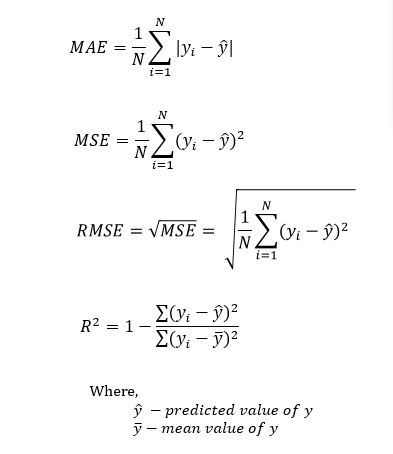

# Метрики

- Основная метрика - RMSE (Root Mean Squared Error).
- Дополнительно рассчитать MAE (Mean Absolute Error).

In [5]:
e_even = np.full(10, 0.5)  # массив из 10 одинаковых ошибок по 0.5.
e_spike = np.array([0] * 9 + [5.0])  #  массив из 9 нулей и одной ошибки 5.0
for name, e in [("Равномерные ошибки", e_even), ("Одна крупная ошибка", e_spike)]:
    print(f"{name}: MAE = {np.abs(e).mean():.2f}, RMSE = {np.sqrt((e ** 2).mean()):.2f}")

Равномерные ошибки: MAE = 0.50, RMSE = 0.50
Одна крупная ошибка: MAE = 0.50, RMSE = 1.58


- **MAE** - средний модуль ошибки: «на сколько баллов quality модель ошибается в среднем». Все ошибки входят линейно, поэтому метрика *устойчива к отдельным выбросам*.
- **RMSE** - корень из среднего квадрата ошибок. Отражает типичную ошибку с повышенным вниманием к крупным промахам.
- **Почему RMSE сильнее реагирует на большие ошибки.** Из-за возведения в квадрат вклад ошибки растёт квадратично. После усреднения крупные промахи доминируют. В примере выше при одинаковом MAE = 0.5 одна ошибка в 5 баллов увеличивает RMSE с 0.5 до ≈ 1.6.
- **Почему MAE и RMSE одной модели могут заметно различаться.** Всегда RMSE ≥ MAE, равенство возможно, только если все ошибки одинаковы по модулю. Чем неравномернее ошибки, тем сильнее RMSE превышает MAE. Для нормально распределённых ошибок RMSE ≈ 1.25·MAE; заметно большее отношение указывает на крупные редкие промахи. Поэтому полезно смотреть на обе метрики сразу.

# Модели

Необходимо обучить и сравнить следующие модели:
- Линейная регрессия
- Random Forest Regressor
- Gradient Boosting Regressor

In [6]:
def fit_eval(name, model):
    models[name] = model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    res[name] = evaluate(y_test, preds[name])
    return pd.Series(res[name]).round(3)

fit_eval("Linear Regression", make_pipeline(StandardScaler(), LinearRegression()))

RMSE    0.637
MAE     0.495
dtype: float64

In [ ]:
coef = pd.DataFrame({"raw": LinearRegression().fit(X_train, y_train).coef_,
                     "standardized": models["Linear Regression"][-1].coef_}, index=X.columns)
# "raw" - коэффициенты «сырой» линейной регрессии (без масштабирования)
# "standardized" - коэффициенты из пайплайна со StandardScaler

coef.loc[coef["standardized"].abs().sort_values(ascending=False).index].round(4)  # Сортируем строки по убыванию, .loc[...] - переставляем строки в этом порядке

,raw,standardized
alcohol,0.2975,0.3169
volatile acidity,-1.0691,-0.1899
sulphates,0.7669,0.1367
total sulfur dioxide,-0.0039,-0.1284
pH,-0.6043,-0.0916
chlorides,-1.6351,-0.0833
free sulfur dioxide,0.0063,0.0659
citric acid,-0.1405,-0.0274
density,-2.2214,-0.0041
residual sugar,0.0020,0.0028


**Результат.** Линейная регрессия заметно лучше baseline: её RMSE 0.64, то есть порог 0.70 она проходит. Но среди трёх моделей она самая слабая: связь признаков с quality частично нелинейная и содержит взаимодействия, которые линейная модель не видит.

**Коэффициенты и масштабирование.**
- Масштабирование **не меняет предсказания и метрики** линейной регрессии, поэтому RMSE и MAE одинаковы со `StandardScaler` и без него.
- Но оно **критично для интерпретации**. «Сырые» коэффициенты зависят от единиц измерения. После `StandardScaler` коэффициент показывает, на сколько баллов меняется quality при росте признака на одно стандартное отклонение, и коэффициенты становятся сопоставимы.
- Наибольшее влияние оказывают признаки в верхней части таблицы стандартизированных коэффициентов (это `alcohol`, `volatile acidity`, `sulphates`, `total sulfur dioxide`, `pH`, `chlorides`), что согласуется с корреляциями из EDA. Интерпретировать коэффициенты нужно осторожно: из-за мультиколлинеарности (`fixed acidity`, `density`, `citric acid`, `pH`) общий эффект делится между связанными признаками.

In [ ]:
fit_eval("Random Forest", RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RS)) 
# n_estimators - количество деревьев в ансамбле, n_jobs - использовать все доступные ядра CPU

RMSE    0.566
MAE     0.417
dtype: float64

Случайный лес улучшает результат по сравнению с линейной моделью (RMSE 0.57) и проходит порог 0.70. Ансамбль глубоких деревьев сам находит нелинейные зависимости и взаимодействия (например, влияние SO₂ или совместное действие `alcohol` и `sulphates`) без ручного конструирования признаков, а усреднение деревьев снижает дисперсию.

In [ ]:
fit_eval("Gradient Boosting", GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=RS))
# learning_rate - вклад каждого дерева (шаг обучения)

RMSE    0.594
MAE     0.441
dtype: float64

Градиентный бустинг тоже лучше линейной регрессии и baseline. При умеренных параметрах, заданных без подбора по тесту, он немного уступает случайному лесу (RMSE 0.59).

# Честное сравнение моделей

Все модели должны сравниваться в одинаковых условиях

In [ ]:
kf = KFold(5, shuffle=True, random_state=RS)
all_models = {"Baseline": baseline, **models}
cv = {n: -cross_val_score(m, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error").mean()
      for n, m in all_models.items()}

table = pd.DataFrame(res).T.assign(CV_RMSE=pd.Series(cv))  # .assign() - метод, который добавляет новый столбец в DataFrame
table["лучше baseline"] = table["RMSE"] < table.loc["Baseline", "RMSE"]
print("Проходят порог RMSE < 0.70:", [n for n, r in table["RMSE"].items() if r < 0.70])
table.round(3)

Проходят порог RMSE < 0.70: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


,RMSE,MAE,CV_RMSE,лучше baseline
Baseline,0.803,0.681,0.808,False
Linear Regression,0.637,0.495,0.657,True
Random Forest,0.566,0.417,0.598,True
Gradient Boosting,0.594,0.441,0.628,True


**Какие модели превзошли baseline.** Все три модели лучше baseline и по RMSE, и по MAE, то есть признаки действительно несут информацию о качестве вина. Порог RMSE < 0.70 проходят все три модели; линейная регрессия ближе всего к порогу. Все модели обучались на одном train и оценивались на одном test, а колонка `CV_RMSE` (5-fold на train, без использования теста) показывает то же ранжирование, то есть результат не является следствием удачного разбиения.

**Почему модели различаются.**
- *LR vs RF:* зависимость quality от признаков частично нелинейна и содержит взаимодействия (эффект `alcohol` зависит от `sulphates` и кислотности). Линейная модель описывает только линейные вклады, к тому же чувствительна к выбросам (тяжёлые хвосты) и мультиколлинеарности. Деревья не требуют масштабирования, устойчивы к выбросам и ловят пороги и взаимодействия.
- *RF vs GB:* лес усредняет глубокие независимые деревья и хорошо работает на небольших зашумлённых табличных данных. Бустинг строит неглубокие деревья последовательно, исправляя ошибки, и сильнее зависит от гиперпараметров (глубина, learning rate, число деревьев), поэтому без подбора может немного уступать лесу. Дополнительно глубокий лес хорошо запоминает обучающие объекты, а в данных ≈ 15% дубликатов, попавших и в train, и в test, что играет в пользу леса и делает его оценку чуть оптимистичнее.

# Feature importance

Для моделей, позволяющих получить feature importance, необходимо:
1. получить значения важности признаков
2. визуализировать их
3. выделить наиболее важные признаки
4. сравнить результаты разных моделей
5. сопоставить их с результатами исследовательского анализа данных

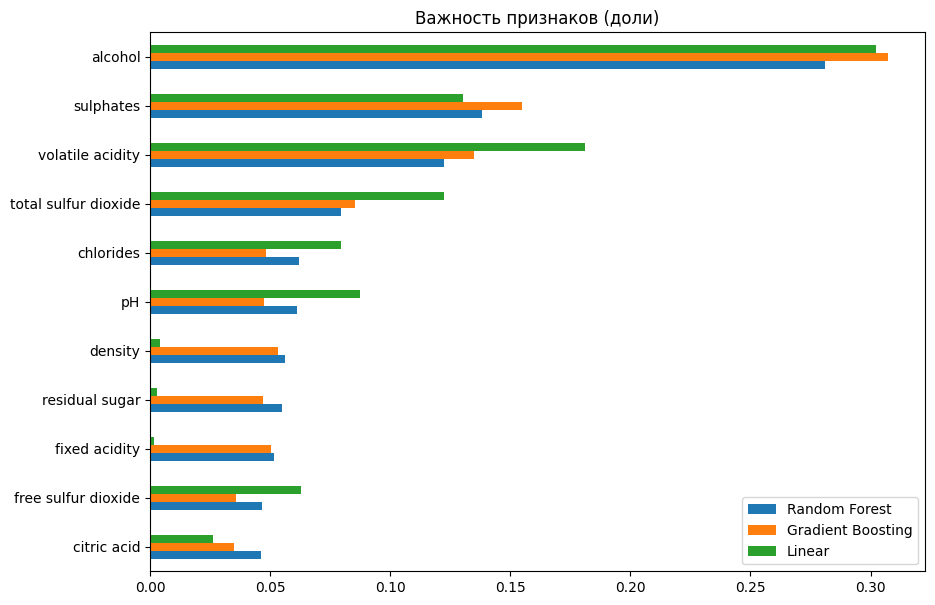

,Random Forest,Gradient Boosting,Linear
alcohol,0.281,0.307,0.302
sulphates,0.138,0.155,0.130
volatile acidity,0.122,0.135,0.181
total sulfur dioxide,0.080,0.085,0.122
chlorides,0.062,0.048,0.079
pH,0.061,0.047,0.087
density,0.056,0.053,0.004
residual sugar,0.055,0.047,0.003
fixed acidity,0.051,0.050,0.002
free sulfur dioxide,0.047,0.036,0.063


In [ ]:
fi = pd.DataFrame({
    "Random Forest": models["Random Forest"].feature_importances_,
    "Gradient Boosting": models["Gradient Boosting"].feature_importances_,
    "Linear": coef["standardized"].abs() / coef["standardized"].abs().sum(),
}, index=X.columns).sort_values("Random Forest")  # Сборка таблицы важностей

fi.plot.barh(figsize=(10, 7), title="Важность признаков (доли)")
plt.show()
fi.sort_values("Random Forest", ascending=False).round(3)

**Наиболее важные признаки.** У обоих ансамблей на первом месте `alcohol`; далее следует группа признаков со сравнимой важностью: `sulphates`, `volatile acidity`, `total sulfur dioxide`.

**Сравнение моделей.** Верхушка у Random Forest и Gradient Boosting совпадает и согласуется с линейной моделью: `alcohol`, `volatile acidity` и `sulphates` лидировали и по корреляции, и по коэффициентам. 

    Различается распределение важности: бустинг сильнее концентрирует вес на нескольких главных признаках (в первую очередь `alcohol`), лес «размазывает» важность по большему числу признаков, особенно скоррелированных (`fixed acidity`, `density`, `citric acid`, `pH`), между которыми она делится. У линейной модели порядок второстепенных признаков другой: из-за коллинеарности её веса распределяются между связанными признаками иначе.

**Сопоставление с EDA.** Подтвердилось, что `alcohol`, `volatile acidity` и `sulphates` - признаки с наибольшими корреляциями с quality. Признаки `residual sugar`, `free sulfur dioxide`, `pH` почти не коррелировали с quality, но у деревьев получают небольшую, но заметную важность. Отчасти это означает, что они информативны нелинейно или в связке с другими признаками. Это подтверждает вывод EDA не отбрасывать слабокоррелированные признаки.

**Можно ли на основании feature importance утверждать, что изменение признака является причиной изменения качества вина? Нет.**
1. Важность показывает, насколько признак полезен модели для *предсказания* на этих данных, а не что произойдёт с quality, если признак изменить.
2. Данные наблюдательные: скрытые общие причины (сорт винограда, регион, зрелость ягод, технология) влияют и на химический состав, и на оценку. Например, высокий `alcohol` может быть маркером зрелого винограда или определённого стиля вина, а не причиной высокой оценки.
3. При скоррелированных признаках (`fixed acidity`, `density`, `citric acid`, `pH`) важность делится между ними почти произвольно, ранжирование зависит от модели (у RF и GB оно различается).

# Анализ ошибок

Необходимо:
- посмотреть распределение ошибок
- найти объекты с наиболее крупными ошибками
- сравнить истинные и предсказанные значения quality
- проверить, одинаково ли хорошо модель работает для разных значений quality

Лучшая модель: Random Forest | доля объектов с |ошибкой| < 1: 0.925


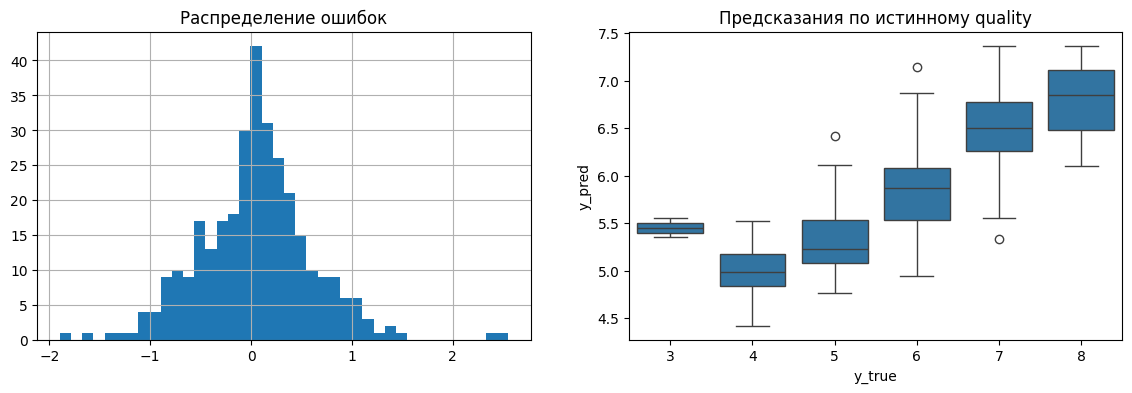

In [12]:
best = table.drop("Baseline")["CV_RMSE"].idxmin()
err = pd.DataFrame({"y_true": y_test, "y_pred": preds[best]})
err["error"] = err["y_pred"] - err["y_true"]
err["abs_error"] = err["error"].abs()
print("Лучшая модель:", best, "| доля объектов с |ошибкой| < 1:", round((err["abs_error"] < 1).mean(), 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
err["error"].hist(bins=40, ax=ax[0])
ax[0].set_title("Распределение ошибок")
sns.boxplot(x="y_true", y="y_pred", data=err, ax=ax[1])
ax[1].set_title("Предсказания по истинному quality")
plt.show()

In [ ]:
# для каждого истинного значения quality вычислякм метрики ошибок; это нужно, чтобы увидеть, где модель ошибается больше - на частых классах или на редких
by_q = err.groupby("y_true").agg(n=("error", "size"), mean_pred=("y_pred", "mean"),
                                  bias=("error", "mean"), MAE=("abs_error", "mean"))  # bias  - средняя ошибка (mean of error)
by_q["RMSE"] = err.groupby("y_true")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
by_q.round(2)

,n,mean_pred,bias,MAE,RMSE
y_true,,,,,
3,2,5.45,2.45,2.45,2.45
4,11,5.00,1.00,1.00,1.04
5,136,5.33,0.33,0.34,0.46
6,128,5.84,-0.16,0.36,0.45
7,40,6.47,-0.53,0.55,0.67
8,3,6.77,-1.23,1.23,1.33


In [ ]:
# ищем объекты с наибольшей ошибкой и выводим их значения по самым важным признакам; это помогает понять, на каких объектах модель «промахнулась сильнее всего»
top = fi["Random Forest"].nlargest(4).index
err.nlargest(8, "abs_error").join(X_test[top]).round(2)

,y_true,y_pred,error,abs_error,alcohol,sulphates,volatile acidity,total sulfur dioxide
1374,3,5.55,2.55,2.55,9.8,0.51,0.82,29.0
832,3,5.35,2.35,2.35,9.9,0.86,0.44,48.0
440,8,6.10,-1.90,1.90,9.8,0.82,0.31,29.0
943,7,5.34,-1.66,1.66,9.7,0.60,0.50,45.0
703,4,5.52,1.52,1.52,9.6,0.70,0.38,84.0
442,7,5.55,-1.45,1.45,11.2,0.68,0.68,43.0
1322,5,6.42,1.42,1.42,11.4,0.55,0.34,18.0
1233,4,5.35,1.35,1.35,9.3,0.49,0.23,36.0


**Распределение ошибок.** Ошибки центрированы около нуля и почти симметричны; для подавляющего большинства объектов |ошибка| < 1 балла. Но есть «хвосты» - отдельные крупные промахи, из-за которых RMSE заметно больше MAE.

**Истинные и предсказанные значения.** Предсказания сосредоточены в узком диапазоне вокруг 5–7, тогда как истинные оценки шире: боксплоты показывают сжатие к центру. Для редких низких оценок (3–4) модель в среднем завышает значение (bias > 0), для высоких (8) - занижает (bias < 0).

**Одинаково ли хорошо работает модель при разных quality?** Нет. Лучше всего она работает на самых частых оценках 5–6 (малые MAE и смещение); на оценках 3, 4, 7 и особенно 8 ошибки и смещение в разы больше.

**Почему редкие значения quality предсказываются хуже.**
- Модель минимизирует суммарную квадратичную ошибку, в которой доминируют частые оценки 5–6; выгоднее предсказывать значения ближе к середине, чем «рисковать» на редких классах.
- Примеров мало (оценок 3 всего 10, оценок 8 - 18, в тесте их единицы): деревья не набирают достаточно объектов в листья, и предсказание усредняется с соседними, более частыми оценками. Усреднение в ансамбле дополнительно сжимает предсказания к центру.
- Химический состав плохо различает соседние оценки, а крайние оценки часто объясняются факторами, которых в данных нет (аромат, сорт, субъективность дегустатора). 

**Объекты с наибольшими ошибками**. Как правило, это вина с истинной оценкой 3–4 или 7–8, которые модель предсказывает как 5–6. По главным признакам (`alcohol`, `volatile acidity` и др.) они выглядят «типично»: низко оценённые вина имеют обычный `alcohol` и невысокую `volatile acidity`, а высоко оценённые - посредственный состав. Возможные причины: шум и субъективность разметки (экстремальная оценка поставлена по неотражённым в данных признакам), редкость класса и почти одинаковый химический состав у вин с разной оценкой.

# Общий вывод

Все модели превзошли baseline (RMSE ≈ 0.8). Лучший результат показали ансамбли деревьев; линейная регрессия чуть слабее, но тоже проходит порог RMSE < 0.70. Главный признак для всех моделей - `alcohol`, затем `volatile acidity`, `sulphates`. Слабое место моделей - редкие значения quality (3, 4, 8): предсказания «сжимаются» к 5–6.